[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/erickmunoz-univalle/erickmunoz-fisica-computacional-2026ii-univalle/blob/main/Calculo_Pi_Montecarlo/taller5_colab.ipynb)

# Taller 5 de  Física Computacional
Solución de Taller 5 del taller de físcia computacional.

**Estudiante:** Erick Alexander Muñoz Orozco

**Lenguaje:** Fortran 2008 y Python

**Tema:** Cálculo de Pi y método Montecarlo



---



**Parte A.  Convergencia del estimador de $\pi$**

In [14]:
%%writefile taller5_pi.f90
! Taller 5 -- Convergencia del estimador de pi por acierto y error.
! Salidas: convergencia.dat (N, media, desviación) y pendiente.dat (pendiente m).
program taller5_pi
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: M = 20                  ! corridas por cada N
  integer :: k, j, n_sem, u_dat, n_puntos
  integer(8) :: i, n_total, n_aciertos
  integer, allocatable :: semilla(:)
  real(dp) :: u, v, x, y, pi_est, suma, suma2, media, desv
  real(dp) :: X_k, Y_k, sx, sy, sxx, sxy, pendiente

  call random_seed(size=n_sem)
  allocate(semilla(n_sem))

  sx = 0.0_dp; sy = 0.0_dp; sxx = 0.0_dp; sxy = 0.0_dp; n_puntos = 0   ! sumas del ajuste
  open(newunit=u_dat,file='convergencia.dat',status='replace')
  do k = 2, 7                                   ! N = 10^2, ..., 10^7
     n_total = 10_8**k
     suma = 0.0_dp; suma2 = 0.0_dp              ! sumas sobre las M corridas
     do j = 1, M
        semilla = 1000*k + j                    ! una semilla distinta por corrida
        call random_seed(put=semilla)
        pi_est = -1.0_dp                        ! valor provisional

        ! TODO A1: obtenga pi_est con n_total puntos uniformes en el cuadrado (sección 2).
        ! Inicializamos el contador de aciertos dentro del círculo unitario
        n_aciertos = 0_8
        do i = 1_8, n_total
           ! Generamos dos números aleatorios uniformes en [0,1)
           call random_number(u)
           call random_number(v)
           ! Mapeamos el intervalo [0,1) a [-1,1) para las coordenadas (x,y)
           x = 2.0_dp*u - 1.0_dp
           y = 2.0_dp*v - 1.0_dp
           ! Verificamos la condición del círculo x^2 + y^2 < 1 (área = pi)
           if (x*x + y*y < 1.0_dp) then
              n_aciertos = n_aciertos + 1_8
           end if
        end do
        ! Estimación de pi = 4 * (puntos dentro) / (puntos totales)
        ! Usamos real(..., dp) para evitar truncamiento por división entera
        pi_est = 4.0_dp * real(n_aciertos, dp) / real(n_total, dp)

        ! TODO A2: acumule lo necessary para la media y la desviación de las M corridas.
        ! Acumulamos la suma lineal y la suma de cuadrados de pi_est
        suma = suma + pi_est
        suma2 = suma2 + pi_est*pi_est
     end do

     media = -1.0_dp; desv = -1.0_dp            ! valores provisionales
     ! TODO A3: calcule la media y la desviación estándar muestral de las M estimaciones.
     ! Calculamos la media muestral de las M corridas
     media = suma / real(M, dp)
     ! Calculamos la desviación estándar muestral s con el factor de corrección M/(M-1)
     desv = sqrt((real(M, dp)/(real(M, dp) - 1.0_dp)) * ((suma2 / real(M, dp)) - media*media))

     write(u_dat,'(i10,2es25.16e3)') n_total,media,desv
     print '(i10,2f12.6)', n_total,media,desv

     ! TODO A4: acumule lo necesario para ajustar log10(desv) contra log10(N).
     ! Variables para la regresión lineal en escala logarítmica: X_k = log10(N), Y_k = log10(s)
     X_k = log10(real(n_total, dp))
     Y_k = log10(desv)
     ! Acumulamos las sumatorios sum(X), sum(Y), sum(X^2) y sum(X*Y)
     sx = sx + X_k
     sy = sy + Y_k
     sxx = sxx + X_k*X_k
     sxy = sxy + X_k*Y_k
     n_puntos = n_puntos + 1
  end do
  close(u_dat)

  pendiente = -1.0_dp                           ! valor provisional
  ! TODO A5: calcule la pendiente del ajuste por mínimos cuadrados.
  ! Fórmula de la pendiente por mínimos cuadrados: m = (n*sxy - sx*sy) / (n*sxx - sx^2)
  pendiente = (real(n_puntos, dp)*sxy - sx*sy) / (real(n_puntos, dp)*sxx - sx*sx)

  open(newunit=u_dat,file='pendiente.dat',status='replace')
  write(u_dat,'(es25.16e3)') pendiente
  close(u_dat)
  print '(a,f9.4)', 'Pendiente de log10(s) contra log10(N): ', pendiente
end program taller5_pi

Overwriting taller5_pi.f90


In [15]:
!rm -f convergencia.dat pendiente.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_pi taller5_pi.f90 && ./taller5_pi

       100    3.134000    0.161714
      1000    3.126600    0.049779
     10000    3.137260    0.015822
    100000    3.142696    0.003486
   1000000    3.141116    0.002166
  10000000    3.141530    0.000400
Pendiente de log10(s) contra log10(N):   -0.5079


Visualización de la Parte A

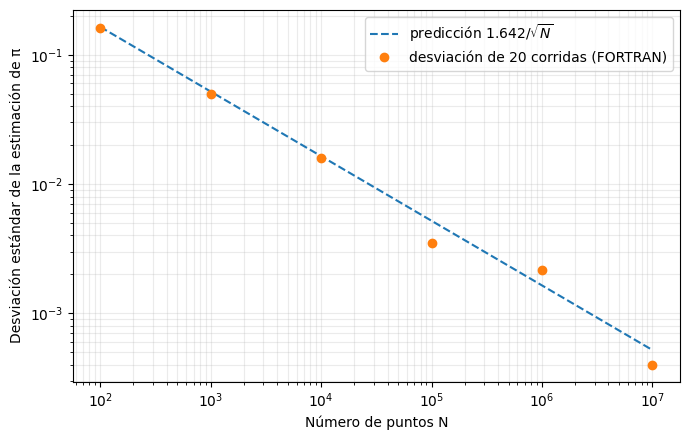

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Lee N, media y desviación calculadas por el programa FORTRAN.
N, media, desv = np.loadtxt('convergencia.dat', ndmin=2).T

plt.figure(figsize=(7,4.5))
plt.loglog(N, 1.642/np.sqrt(N), '--', label=r'predicción $1.642/\sqrt{N}$')
if np.any(desv > 0):
    plt.loglog(N[desv > 0], desv[desv > 0], 'o', label='desviación de 20 corridas (FORTRAN)')
plt.xlabel('Número de puntos N')
plt.ylabel('Desviación estándar de la estimación de π')
plt.grid(True, which='both', alpha=.25)
plt.legend()
plt.tight_layout()
plt.savefig('convergencia_pi.png', dpi=180)
plt.show()

**Parte B. Integral en 1D por dos métodos**

In [17]:
%%writefile taller5_seno.f90
! Taller 5 -- Integral de sin(x) en [0,pi/2) por valor medio y acierto y error.
! Salida: seno.dat (media_vm, desv_vm, media_ae, desv_ae).
program taller5_seno
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: N = 1000, R = 1000      ! muestras por corrida y repeticiones
  real(dp), parameter :: a = 0.0_dp, b = 2.0_dp*atan(1.0_dp), H = 1.0_dp
  integer :: rep, i, n_bajo, n_sem, u_dat
  integer, allocatable :: semilla(:)
  real(dp) :: u, v, x, y, suma_f, I_vm, I_ae
  real(dp) :: s_vm, s2_vm, s_ae, s2_ae, media_vm, desv_vm, media_ae, desv_ae

  ! El tamaño del arreglo de semilla depende de la implementación.
  call random_seed(size=n_sem)
  allocate(semilla(n_sem))
  semilla = 314
  call random_seed(put=semilla)                ! se fija una vez, antes de las R corridas

  s_vm = 0.0_dp; s2_vm = 0.0_dp; s_ae = 0.0_dp; s2_ae = 0.0_dp
  do rep = 1, R
     ! Valores provisionales: reemplácelos dentro de los bloques TODO.
     I_vm = -1.0_dp
     I_ae = -1.0_dp

     ! TODO B1: obtenga I_vm por valor medio usando N puntos (sección 4).
     ! Sumamos f(x) = sin(x) para N puntos x distribuidos uniformemente en [a, b)
     suma_f = 0.0_dp
     do i = 1, N
        call random_number(u)
        x = a + (b - a)*u
        suma_f = suma_f + sin(x)
     end do
     ! I_vm = (ancho del intervalo) * (promedio de f(x))
     I_vm = (b - a) * suma_f / real(N, dp)

     ! TODO B2: obtenga I_ae por acierto y error en [a,b) x [0,H) (sección 4).
     ! Contamos cuántos puntos (x,y) dentro de [a,b) x [0,H) caen por debajo de sin(x)
     n_bajo = 0
     do i = 1, N
        call random_number(u)
        call random_number(v)
        x = a + (b - a)*u
        y = H * v
        if (y < sin(x)) then
           n_bajo = n_bajo + 1
        end if
     end do
     ! I_ae = (área del rectángulo [a,b] x [0,H]) * (fracción de puntos bajo la curva)
     I_ae = (b - a) * H * real(n_bajo, dp) / real(N, dp)

     ! TODO B3: acumule las dos integrales y sus cuadrados para las R corridas.
     ! Acumulamos sumas lineales y de cuadrados para las R repeticiones de ambos métodos
     s_vm  = s_vm  + I_vm
     s2_vm = s2_vm + I_vm*I_vm
     s_ae  = s_ae  + I_ae
     s2_ae = s2_ae + I_ae*I_ae
  end do

  ! Los valores -1 indican que aún no se calcularon las estadísticas.
  media_vm = -1.0_dp; desv_vm = -1.0_dp
  media_ae = -1.0_dp; desv_ae = -1.0_dp
  ! TODO B4: calcule media y desviación estándar muestral para cada método.
  ! Calculamos la media muestral para cada método sobre R repeticiones
  media_vm = s_vm / real(R, dp)
  media_ae = s_ae / real(R, dp)

  ! Calculamos la desviación estándar muestral s con el factor de corrección R/(R-1)
  desv_vm = sqrt((real(R, dp)/(real(R, dp) - 1.0_dp)) * ((s2_vm / real(R, dp)) - media_vm*media_vm))
  desv_ae = sqrt((real(R, dp)/(real(R, dp) - 1.0_dp)) * ((s2_ae / real(R, dp)) - media_ae*media_ae))

  ! Cuatro números sin encabezado para la lectura automática.
  open(newunit=u_dat,file='seno.dat',status='replace')
  write(u_dat,'(4es25.16e3)') media_vm,desv_vm,media_ae,desv_ae
  close(u_dat)
  print '(a,2f10.5)', 'Valor medio (media, desviacion): ',media_vm,desv_vm
  print '(a,2f10.5)', 'Acierto y error (media, desviacion): ',media_ae,desv_ae
end program taller5_seno

Overwriting taller5_seno.f90


In [18]:
!rm -f seno.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_seno taller5_seno.f90 && ./taller5_seno

Valor medio (media, desviacion):    0.99973   0.01529
Acierto y error (media, desviacion):    1.00009   0.02465


**Parte C. Efecto del generador deficiente**

In [19]:
%%writefile taller5_lcg.f90
! Taller 5 -- pi por acierto y error con el LCG (57, 1, 256) en lugar de random_number.
! Salida: lcg.dat (N, pi_est).
program taller5_lcg
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: a_lcg = 57, c_lcg = 1, M_lcg = 256
  integer :: k, r, u_dat
  integer(8) :: i, n_total, n_aciertos
  real(dp) :: x, y, pi_est

  open(newunit=u_dat,file='lcg.dat',status='replace')
  do k = 2, 7                                   ! N = 10^2, ..., 10^7
     n_total = 10_8**k
     r = 10                                     ! semilla del LCG, la misma para cada N
     pi_est = -1.0_dp                           ! valor provisional

     ! TODO C1: obtenga pi_est con n_total puntos cuyas coordenadas salen del LCG (sección 5).
     ! Inicializamos el contador de aciertos dentro del círculo unitario
     n_aciertos = 0_8
     do i = 1_8, n_total
        ! Primer avance del LCG para la coordenada x en [-1, 1)
        r = mod(a_lcg*r + c_lcg, M_lcg)
        x = 2.0_dp*real(r, dp)/real(M_lcg, dp) - 1.0_dp

        ! Segundo avance del LCG para la coordenada y en [-1, 1)
        r = mod(a_lcg*r + c_lcg, M_lcg)
        y = 2.0_dp*real(r, dp)/real(M_lcg, dp) - 1.0_dp

        ! Condición de pertenencia al círculo unitario x^2 + y^2 < 1
        if (x*x + y*y < 1.0_dp) then
           n_aciertos = n_aciertos + 1_8
        end if
     end do
     ! Estimación de pi = 4 * (aciertos / N)
     pi_est = 4.0_dp * real(n_aciertos, dp) / real(n_total, dp)

     write(u_dat,'(i10,es25.16e3)') n_total,pi_est
     print '(i10,f12.6)', n_total,pi_est
  end do
  close(u_dat)
end program taller5_lcg

Overwriting taller5_lcg.f90


In [20]:
!rm -f lcg.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_lcg taller5_lcg.f90 && ./taller5_lcg

       100    3.040000
      1000    3.084000
     10000    3.093200
    100000    3.093720
   1000000    3.093740
  10000000    3.093750


**Parte D. Interpretación**


**1. Con la pendiente de la Parte A, ¿cuántos puntos se necesitarían para obtener $\pi$ con un error de $10^{-6}$ ¿Es práctico?**

R// Con la pendiente m = -0.5079, se necesitan $2.7 * 10^{12}$ puntos para obtener pi con un error de $10^{-6}$. No es práctico, debido a que requeriría mucho tiempo de cómputo generar esa cantidad de puntos aleatorios, mostrando la lenta convergencia del método Montecarlo frente a otros métodos computacionales existentes.

**2. Con el mismo $N$, ¿cuál método de la Parte B tiene menor dispersión? ¿Por qué? ¿Bastaría una sola corrida para afirmarlo?**

R// El método del valor medio (VM) tiene la menor dispersión (0.01529), dado que a diferencia del método de Acierto y Error, esta utiliza la información continua de la función en los puntos de muestreo. Sin embargo, no basta con una sola corrida para afirmar esto. Por esta razón, en este taller se utilizaron múltiples repeticiones (R = 1000), así calculamos la desviación estándar y comparamos las disperciones de manera más rigurosa.

**3. ¿Por qué, con el LCG de la Parte C, aumentar $N$ no reduce el error, aunque cada número esté en $[0,1)$?**

R// Al usar LGC, no se reduce el error aumentando $N$ ya que el LGC tiene un periodo muy corto, con lo cual al aumentar $N$ por encima de ese periodo, los puntos se repiten y el error se vuelve sistemático, sin importar que tanto se aumente $N$.

**4. ¿Por qué el cálculo de $\pi$ es una integral en 2D, aunque su estimador se escriba como una fracción?**

R// El estimador se escribe como una fracción dada que esta es la aproximación del área mediante el método montecarlo. Dado que estamos calculando un área, esta es una integral doble que depende de dos variables, pero si usamos el método montecarlo, la naturaleza estocástica permite expresar el área mediante la frácción de puntos dentro sobre puntos fuera.



**Verificación final PASS/FAIL**

In [21]:
from pathlib import Path
import numpy as np

veredictos = []
def informar(nombre, condicion, detalle=''):
    estado = 'PASS' if condicion else 'FAIL'
    veredictos.append(bool(condicion))
    print(f'{estado} | {nombre}' + (f' — {detalle}' if detalle else ''))

def leer_salida(archivo, fuente, columnas):
    ruta, programa = Path(archivo), Path(fuente)
    if not programa.exists() or not ruta.exists():
        raise ValueError(f'Falta {archivo} o {fuente}; ejecute ambas celdas del programa.')
    if ruta.stat().st_mtime < programa.stat().st_mtime:
        raise ValueError(f'{archivo} es anterior a {fuente}; compile y ejecute otra vez.')
    datos = np.loadtxt(ruta, ndmin=2)
    if datos.shape[1] != columnas or not np.isfinite(datos).all():
        raise ValueError(f'Formato o valores incorrectos en {archivo}.')
    return datos

niveles = 10.0**np.arange(2, 8)                # N = 10^2, ..., 10^7

# --- Parte A: media y dispersión de 20 corridas; pendiente calculada en FORTRAN ---
try:
    filas = leer_salida('convergencia.dat','taller5_pi.f90',3)
    if filas.shape != (6,3) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    n, media, desv = filas.T
    sigma = 1.642/np.sqrt(n)
    ok = (abs(media[4]-np.pi) < 6*sigma[4]/np.sqrt(20)
          and np.all((.45*sigma < desv) & (desv < 1.6*sigma)))
    informar('Convergencia de pi', ok,
             f'media(N=10^6)={media[4]:.6f}, s(N=10^6)={desv[4]:.6f}, predicción={sigma[4]:.6f}')
except Exception as error:
    informar('Convergencia de pi',False,str(error))

try:
    n, media, desv = leer_salida('convergencia.dat','taller5_pi.f90',3).T
    m = leer_salida('pendiente.dat','taller5_pi.f90',1)[0,0]
    if len(n) != 6 or not np.all(desv > 0):
        raise ValueError('convergencia.dat debe tener seis desviaciones positivas.')
    m_datos = np.polyfit(np.log10(n), np.log10(desv), 1)[0]
    informar('Pendiente del ajuste en FORTRAN', -.6 < m < -.4 and abs(m-m_datos) < 1e-4,
             f'm={m:.4f}, predicción=-0.5')
except Exception as error:
    informar('Pendiente del ajuste en FORTRAN',False,str(error))

# --- Parte B: integral de sin x por dos métodos ---
try:
    filas = leer_salida('seno.dat','taller5_seno.f90',4)
    if filas.shape != (1,4):
        raise ValueError('seno.dat debe contener media y desviación de cada método.')
    vm, svm, ae, sae = filas[0]
    n, repeticiones = 1000,1000
    sigma_vm = np.sqrt(np.pi**2/8-1)/np.sqrt(n)
    sigma_ae = np.sqrt(np.pi/2-1)/np.sqrt(n)
    ok_vm = (abs(vm-1)<6*sigma_vm/np.sqrt(repeticiones)
             and .65*sigma_vm < svm < 1.35*sigma_vm)
    ok_ae = (abs(ae-1)<6*sigma_ae/np.sqrt(repeticiones)
             and .65*sigma_ae < sae < 1.35*sigma_ae)
    informar('Integral 1D, valor medio',ok_vm,
             f'media={vm:.6f}, dispersión={svm:.6f}')
    informar('Integral 1D, acierto y error',ok_ae,
             f'media={ae:.6f}, dispersión={sae:.6f}')
except Exception as error:
    informar('Integral 1D, valor medio',False,str(error))
    informar('Integral 1D, acierto y error',False,'Revise el mismo programa.')

# --- Parte C: con el LCG la estimación se estanca lejos de pi ---
try:
    filas = leer_salida('lcg.dat','taller5_lcg.f90',2)
    if filas.shape != (6,2) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    pi_lcg = filas[:,1]
    error_lcg = abs(pi_lcg - np.pi)
    ok = .02 < error_lcg[-1] < .2 and abs(pi_lcg[-1]-pi_lcg[-3]) < 1e-3
    informar('Generador deficiente', ok,
             f'|error| con N=10^5: {error_lcg[-3]:.4f}; con N=10^7: {error_lcg[-1]:.4f}')
except Exception as error:
    informar('Generador deficiente',False,str(error))

print(f'\nRESUMEN: {sum(veredictos)}/{len(veredictos)} PASS')
print('Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.')

PASS | Convergencia de pi — media(N=10^6)=3.141116, s(N=10^6)=0.002166, predicción=0.001642
PASS | Pendiente del ajuste en FORTRAN — m=-0.5079, predicción=-0.5
PASS | Integral 1D, valor medio — media=0.999731, dispersión=0.015292
PASS | Integral 1D, acierto y error — media=1.000085, dispersión=0.024645
PASS | Generador deficiente — |error| con N=10^5: 0.0479; con N=10^7: 0.0478

RESUMEN: 5/5 PASS
Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.




---



**Anexo A — Teorema central del límite (opcional)**

In [22]:
%%writefile tcl_uniforme.f90
! Anexo A -- Promedios de N uniformes (teorema central del límite)
program tcl_uniforme
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: R = 100000              ! número de promedios por cada N
  integer :: rep, c, j, n_sem, u_dat
  integer :: lista_N(4) = [1, 2, 5, 20]
  integer, allocatable :: semilla(:)
  real(dp) :: u, suma, promedio(4)

  call random_seed(size=n_sem)
  allocate(semilla(n_sem))
  semilla = 2026
  call random_seed(put=semilla)

  open(newunit=u_dat, file='tcl.dat', status='replace')
  do rep = 1, R
     do c = 1, 4                                ! un promedio para cada N
        suma = 0.0_dp
        do j = 1, lista_N(c)
           call random_number(u);  suma = suma + u
        end do
        promedio(c) = suma/lista_N(c)
     end do
     write(u_dat, '(4f10.6)') promedio
  end do
  close(u_dat)
end program tcl_uniforme

Overwriting tcl_uniforme.f90


In [23]:
!gfortran -O2 -fcheck=all tcl_uniforme.f90 -o tcl_uniforme && ./tcl_uniforme

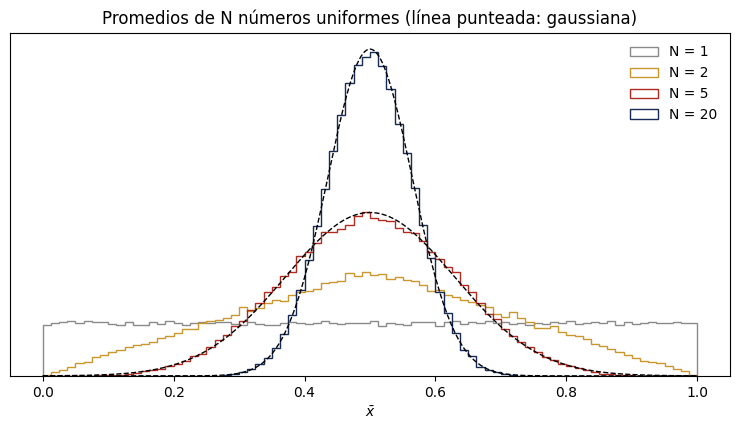

In [24]:
# Histogramas de los promedios y gaussiana del teorema
import numpy as np
import matplotlib.pyplot as plt
datos = np.loadtxt("tcl.dat")
xs = np.linspace(0, 1, 400)
plt.figure(figsize=(7.5, 4.4))
for col, (N, color) in enumerate(zip([1, 2, 5, 20], ["#8A8A8A", "#C9972C", "#B02A20", "#162A54"])):
    plt.hist(datos[:, col], bins=np.linspace(0, 1, 81), density=True, histtype="step",
             lw=1.6, color=color, label=f"N = {N}")
    if N >= 5:
        s = np.sqrt(1/12)/np.sqrt(N)
        plt.plot(xs, np.exp(-(xs - 0.5)**2/(2*s**2))/(np.sqrt(2*np.pi)*s), "k--", lw=1)
plt.xlabel(r"$\bar x$"); plt.yticks([]); plt.legend(frameon=False)
plt.title("Promedios de N números uniformes (línea punteada: gaussiana)")
plt.tight_layout(); plt.show()



---

